In [30]:
import os, sys, copy, subprocess, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42

def set_seed(seed=SEED):
    np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device :", device)

PyTorch 2.11.0+cpu | device : cpu


## 0. Chargement des données

In [31]:
FILE = "prices-split-adjusted.csv"
CANDIDATES = [f"/kaggle/input/nyse/{FILE}", f"/content/{FILE}", f"data/{FILE}", FILE]
path = next((p for p in CANDIDATES if os.path.exists(p)), None)

if path is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
    import kagglehub
    path = os.path.join(kagglehub.dataset_download("dgawlik/nyse"), FILE)


df = pd.read_csv(path, parse_dates=["date"])
df = df.sort_values(["symbol", "date"]).reset_index(drop=True)
df.head()

,date,symbol,open,close,low,high,volume
0,2010-01-04,A,22.453504,22.389128,22.267525,22.625180,3815500.0
1,2010-01-05,A,22.324749,22.145923,22.002861,22.331903,4186000.0
2,2010-01-06,A,22.067240,22.067240,22.002861,22.174536,3243700.0
3,2010-01-07,A,22.017168,22.038626,21.816881,22.045780,3095100.0
4,2010-01-08,A,21.917024,22.031474,21.745350,22.067240,3733900.0


## 1. Analyse exploratoire des données (EDA)

In [32]:
print("Dimensions :", df.shape)
print("Période    :", df["date"].min().date(), "→", df["date"].max().date())
print("Nombre d'actions (symbol) :", df["symbol"].nunique())
print("\nTypes :\n", df.dtypes)
print("\nValeurs manquantes :\n", df.isna().sum())
print("\nDoublons (date, symbol) :", df.duplicated(["date", "symbol"]).sum())
df.describe().T

Dimensions : (851264, 7)
Période    : 2010-01-04 → 2016-12-30
Nombre d'actions (symbol) : 501

Types :
 date      datetime64[ns]
symbol            object
open             float64
close            float64
low              float64
high             float64
volume           float64
dtype: object

Valeurs manquantes :
 date      0
symbol    0
open      0
close     0
low       0
high      0
volume    0
dtype: int64

Doublons (date, symbol) : 0


,count,mean,min,25%,50%,75%,max,std
date,851264,2013-07-21 02:56:29.294037760,2010-01-04 00:00:00,2011-10-19 00:00:00,2013-08-02 00:00:00,2015-04-24 00:00:00,2016-12-30 00:00:00,NaN
open,851264.0,64.993618,1.66,31.27,48.459999,75.120003,1584.439941,75.203893
close,851264.0,65.011913,1.59,31.292776,48.48,75.139999,1578.130005,75.201216
low,851264.0,64.336541,1.5,30.940001,47.970001,74.400002,1549.939941,74.459518
high,851264.0,65.639748,1.81,31.620001,48.959999,75.849998,1600.930054,75.906861
volume,851264.0,5415112.640027,0.0,1221500.0,2476250.0,5222500.0,859643400.0,12494681.433083


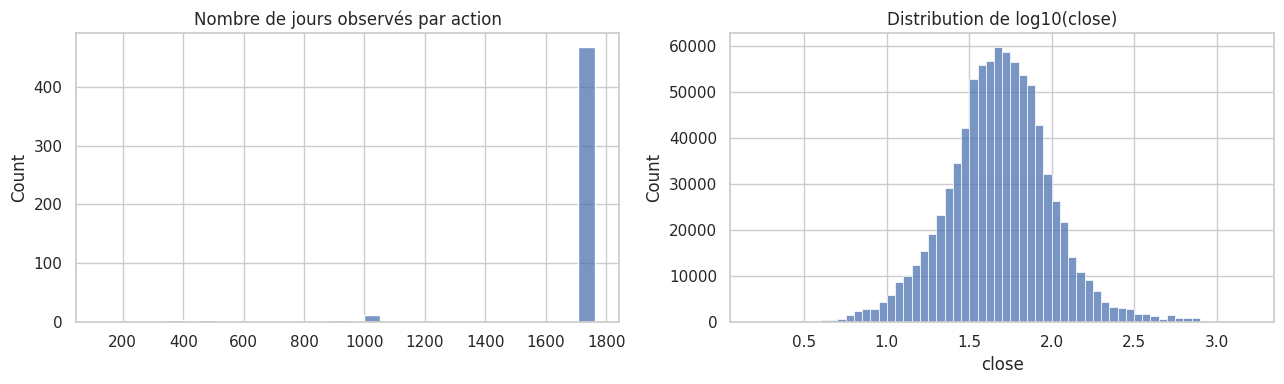

In [33]:
counts = df.groupby("symbol").size()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(counts, bins=30, ax=ax[0]); ax[0].set_title("Nombre de jours observés par action")
sns.histplot(np.log10(df["close"]), bins=60, ax=ax[1]); ax[1].set_title("Distribution de log10(close)")
plt.tight_layout(); plt.show()

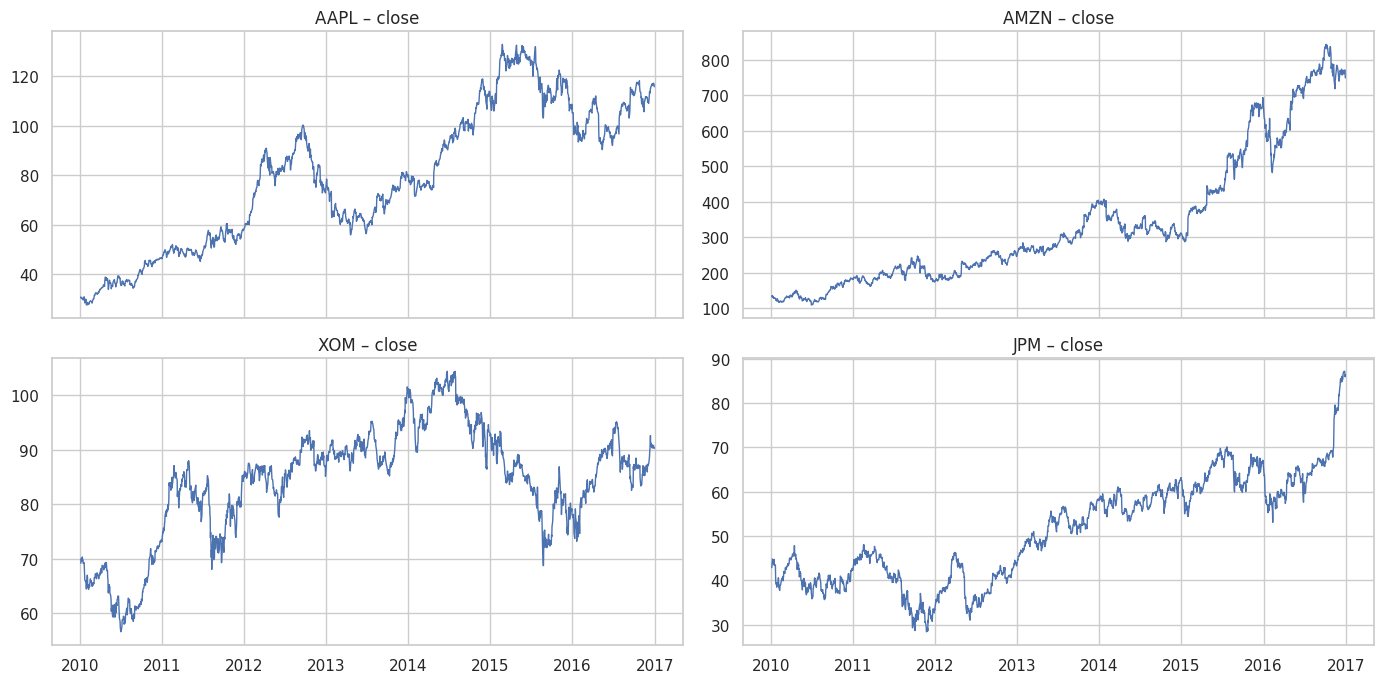

In [34]:
wanted = ["AAPL", "AMZN", "XOM", "JPM", "WMT", "GE"]
syms = [s for s in wanted if s in set(df["symbol"])][:4] or list(df["symbol"].unique()[:4])
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
for ax, s in zip(axes.ravel(), syms):
    d = df[df.symbol == s]
    ax.plot(d["date"], d["close"], lw=1); ax.set_title(f"{s} – close")
plt.tight_layout(); plt.show()

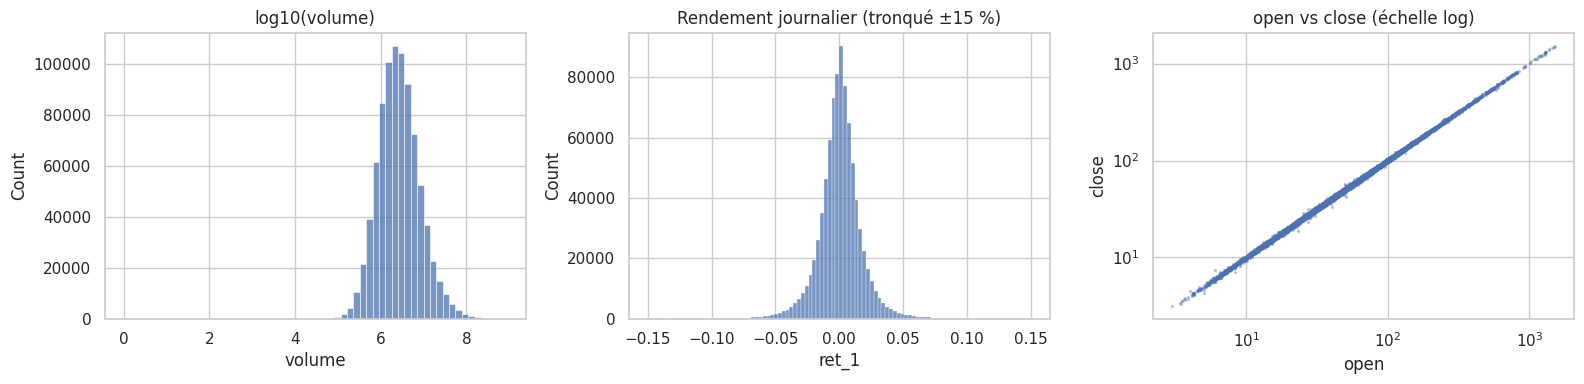

Kurtosis des rendements : 424.7 → queues très épaisses (valeurs extrêmes fréquentes)


In [35]:
df["ret_1"] = df.groupby("symbol")["close"].pct_change()
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(np.log10(df["volume"].clip(lower=1)), bins=60, ax=ax[0]); ax[0].set_title("log10(volume)")
sns.histplot(df["ret_1"].clip(-0.15, 0.15).dropna(), bins=100, ax=ax[1]); ax[1].set_title("Rendement journalier (tronqué ±15 %)")
sample = df.sample(min(len(df), 30000), random_state=SEED)
ax[2].scatter(sample["open"], sample["close"], s=2, alpha=0.3); ax[2].set_xscale("log"); ax[2].set_yscale("log")
ax[2].set_title("open vs close (échelle log)"); ax[2].set_xlabel("open"); ax[2].set_ylabel("close")
plt.tight_layout(); plt.show()
print("Kurtosis des rendements :", round(df["ret_1"].kurt(), 1), "→ queues très épaisses (valeurs extrêmes fréquentes)")

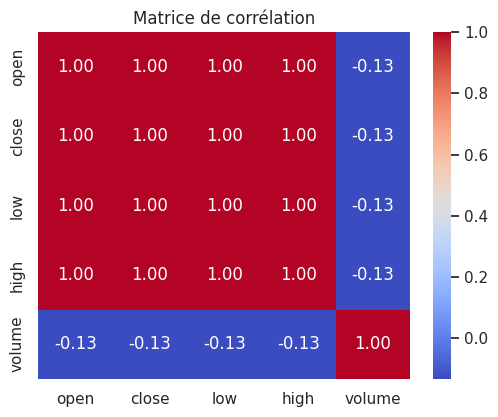

In [36]:
plt.figure(figsize=(6, 4.5))
sns.heatmap(df[["open", "close", "low", "high", "volume"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matrice de corrélation"); plt.show()

In [37]:
g = df.groupby("symbol")
df["ma5"]  = g["close"].transform(lambda s: s.rolling(5).mean())
df["ma10"] = g["close"].transform(lambda s: s.rolling(10).mean())
df["vol5"] = df.groupby("symbol")["ret_1"].transform(lambda s: s.rolling(5).std())
df["target"] = g["close"].shift(-1)

df = df[(df[["open", "high", "low", "close", "ma5", "ma10"]] > 0).all(axis=1)]
data = df.dropna(subset=["ret_1", "ma5", "ma10", "vol5", "target"]).copy()
data = data.sort_values("date", kind="stable").reset_index(drop=True)   # tri chronologique

X_raw = pd.DataFrame({
    "log_open": np.log(data["open"]), "log_high": np.log(data["high"]),
    "log_low": np.log(data["low"]),   "log_close": np.log(data["close"]),
    "log_ma5": np.log(data["ma5"]),   "log_ma10": np.log(data["ma10"]),
    "ret_1": data["ret_1"].clip(-0.5, 0.5), "vol5": data["vol5"],
    "log_volume": np.log1p(data["volume"]),
})
y_log = np.log(data["target"]).values
FEATURES = list(X_raw.columns)

dates = np.sort(data["date"].unique())
d_val, d_test = dates[int(len(dates) * 0.70)], dates[int(len(dates) * 0.80)]
is_tr, is_te = (data["date"] < d_val).values, (data["date"] >= d_test).values
is_va = ~(is_tr | is_te)
print(f"train : {is_tr.sum():,} | val : {is_va.sum():,} | test : {is_te.sum():,}")
print("Test à partir du", pd.Timestamp(d_test).date())

sx = StandardScaler().fit(X_raw[is_tr])
sy = StandardScaler().fit(y_log[is_tr].reshape(-1, 1))
Y_MU, Y_SD = float(sy.mean_[0]), float(sy.scale_[0])
X_tr, X_va, X_te = (sx.transform(X_raw[m]).astype(np.float32) for m in (is_tr, is_va, is_te))
y_tr, y_va, y_te = (sy.transform(y_log[m].reshape(-1, 1)).ravel().astype(np.float32) for m in (is_tr, is_va, is_te))

TOL = 0.02
TOL_SCALED = float(np.log1p(TOL) / Y_SD)
to_price = lambda ps: np.exp(np.asarray(ps) * Y_SD + Y_MU)
close_now = {"train": data.loc[is_tr, "close"].values, "test": data.loc[is_te, "close"].values}
meta_te = data.loc[is_te, ["date", "symbol"]].reset_index(drop=True)

train : 584,502 | val : 86,380 | test : 175,372
Test à partir du 2015-08-11


## 3. Architecture DNN


In [38]:
class MLP(nn.Module):
    ACT = {"relu": nn.ReLU, "tanh": nn.Tanh, "leaky_relu": nn.LeakyReLU, "gelu": nn.GELU}
    def __init__(self, in_dim, out_dim, hidden=(64, 32), activation="relu", dropout=0.0, batch_norm=False):
        super().__init__()
        layers, d = [], in_dim
        for h in hidden:
            layers.append(nn.Linear(d, h))
            if batch_norm: layers.append(nn.BatchNorm1d(h))
            layers.append(self.ACT[activation]())
            if dropout > 0: layers.append(nn.Dropout(dropout))
            d = h
        layers.append(nn.Linear(d, out_dim))
        self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)

def make_optimizer(name, params, lr, weight_decay):
    name = name.lower()
    if name == "adam":    return torch.optim.Adam(params, lr=lr, weight_decay=weight_decay)
    if name == "adamw":   return torch.optim.AdamW(params, lr=lr, weight_decay=weight_decay)
    if name == "sgd":     return torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=weight_decay)
    if name == "rmsprop": return torch.optim.RMSprop(params, lr=lr, weight_decay=weight_decay)
    raise ValueError(name)

class TorchMLPRegressor(RegressorMixin, BaseEstimator):
    def __init__(self, hidden=(64, 32), activation="relu", lr=1e-3, optimizer="adam", epochs=30,
                 batch_size=256, dropout=0.0, weight_decay=0.0, batch_norm=False,
                 patience=None, tol_scaled=0.1, random_state=SEED):
        self.hidden = hidden; self.activation = activation; self.lr = lr; self.optimizer = optimizer
        self.epochs = epochs; self.batch_size = batch_size; self.dropout = dropout
        self.weight_decay = weight_decay; self.batch_norm = batch_norm; self.patience = patience
        self.tol_scaled = tol_scaled; self.random_state = random_state

    def _predict_scaled(self, X):
        self.model_.eval(); out = []
        X = torch.as_tensor(np.asarray(X, dtype=np.float32))
        with torch.no_grad():
            for i in range(0, len(X), 8192):
                out.append(self.model_(X[i:i + 8192].to(device)).squeeze(-1).cpu().numpy())
        return np.concatenate(out)

    def _mse_acc(self, X, y):
        p = self._predict_scaled(X)
        return float(np.mean((p - y) ** 2)), float(np.mean(np.abs(p - y) <= self.tol_scaled))

    def fit(self, X, y, val_set=None, eval_sets=None):
        set_seed(self.random_state)
        X = np.asarray(X, dtype=np.float32); y = np.asarray(y, dtype=np.float32)
        self.model_ = MLP(X.shape[1], 1, self.hidden, self.activation, self.dropout, self.batch_norm).to(device)
        opt = make_optimizer(self.optimizer, self.model_.parameters(), self.lr, self.weight_decay)
        loss_fn = nn.MSELoss()
        loader = DataLoader(TensorDataset(torch.from_numpy(X), torch.from_numpy(y)),
                            batch_size=self.batch_size, shuffle=True, drop_last=len(X) > self.batch_size)
        self.history_ = {}
        best_val, best_state, wait, self.best_epoch_ = np.inf, None, 0, self.epochs
        sets = dict(eval_sets or {})
        if val_set is not None: sets["val"] = val_set
        for ep in range(self.epochs):
            self.model_.train()
            for xb, yb in loader:
                xb, yb = xb.to(device), yb.to(device)
                opt.zero_grad(); loss = loss_fn(self.model_(xb).squeeze(-1), yb); loss.backward(); opt.step()
            for name, (Xe, ye) in sets.items():
                l, a = self._mse_acc(Xe, ye)
                h = self.history_.setdefault(name, {"loss": [], "acc": []}); h["loss"].append(l); h["acc"].append(a)
            if self.patience is not None and val_set is not None:
                vl = self.history_["val"]["loss"][-1]
                if vl < best_val - 1e-6:
                    best_val, best_state, wait, self.best_epoch_ = vl, copy.deepcopy(self.model_.state_dict()), 0, ep + 1
                else:
                    wait += 1
                    if wait >= self.patience: break
        if best_state is not None: self.model_.load_state_dict(best_state)
        return self

    def predict(self, X): return self._predict_scaled(X)
    def score(self, X, y): return r2_score(y, self.predict(X))

print("Architecture d'exemple :\n", MLP(len(FEATURES), 1, (64, 32), "relu", 0.2, True))

Architecture d'exemple :
 MLP(
  (net): Sequential(
    (0): Linear(in_features=9, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=32, out_features=1, bias=True)
  )
)


## 4. Recherche des hyperparamètres avec `GridSearchCV`



In [39]:
rng = np.random.default_rng(SEED)
n_sub = 20000
idx = np.sort(rng.choice(len(X_tr), size=min(n_sub, len(X_tr)), replace=False))   # ordre chronologique conservé

param_grid = {
    "hidden": [(32,), (64, 32), (128, 64, 32)],
    "lr": [1e-3, 1e-2],
    "optimizer": ["adam", "sgd"],
    "epochs": [20, 40],
}

gs = GridSearchCV(TorchMLPRegressor(batch_size=256, tol_scaled=TOL_SCALED), param_grid,
                  cv=TimeSeriesSplit(n_splits=3), scoring="r2", n_jobs=1, refit=False, verbose=1)
gs.fit(X_tr[idx], y_tr[idx])

res = pd.DataFrame(gs.cv_results_).sort_values("rank_test_score")
cols = ["param_hidden", "param_lr", "param_optimizer", "param_epochs", "mean_test_score", "std_test_score", "mean_fit_time"]
display(res[cols].head(10).reset_index(drop=True))
best_params = res.iloc[0]["params"]
print("\nMeilleurs hyperparamètres :", best_params)

Fitting 3 folds for each of 24 candidates, totalling 72 fits


,param_hidden,param_lr,param_optimizer,param_epochs,mean_test_score,std_test_score,mean_fit_time
0,"(128, 64, 32)",0.001,adam,40,0.999259,0.000270,6.312956
1,"(32,)",0.010,adam,40,0.999254,0.000245,4.394643
2,"(128, 64, 32)",0.010,adam,20,0.999253,0.000257,3.315740
3,"(128, 64, 32)",0.001,adam,20,0.999252,0.000258,3.273306
4,"(64, 32)",0.010,adam,20,0.999232,0.000246,2.654317
5,"(64, 32)",0.001,adam,40,0.999223,0.000257,4.895136
6,"(32,)",0.010,adam,20,0.999209,0.000311,2.418354
7,"(128, 64, 32)",0.010,sgd,40,0.999179,0.000291,5.184736
8,"(64, 32)",0.001,adam,20,0.999161,0.000334,2.657116
9,"(64, 32)",0.010,sgd,40,0.999157,0.000292,4.439439



Meilleurs hyperparamètres : {'epochs': 40, 'hidden': (128, 64, 32), 'lr': 0.001, 'optimizer': 'adam'}


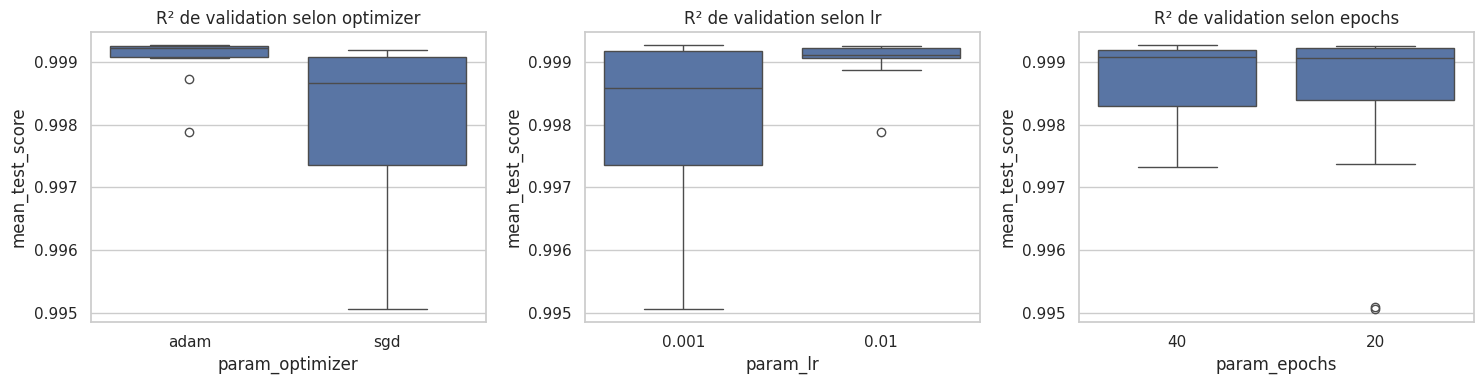

In [40]:
# Influence de chaque hyperparamètre sur le score de validation
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ["param_optimizer", "param_lr", "param_epochs"]):
    sns.boxplot(data=res.assign(**{c: res[c].astype(str)}), x=c, y="mean_test_score", ax=ax)
    ax.set_title(f"R² de validation selon {c.replace('param_', '')}")
plt.tight_layout(); plt.show()

## 5. Modèle de base : entraînement complet et courbes


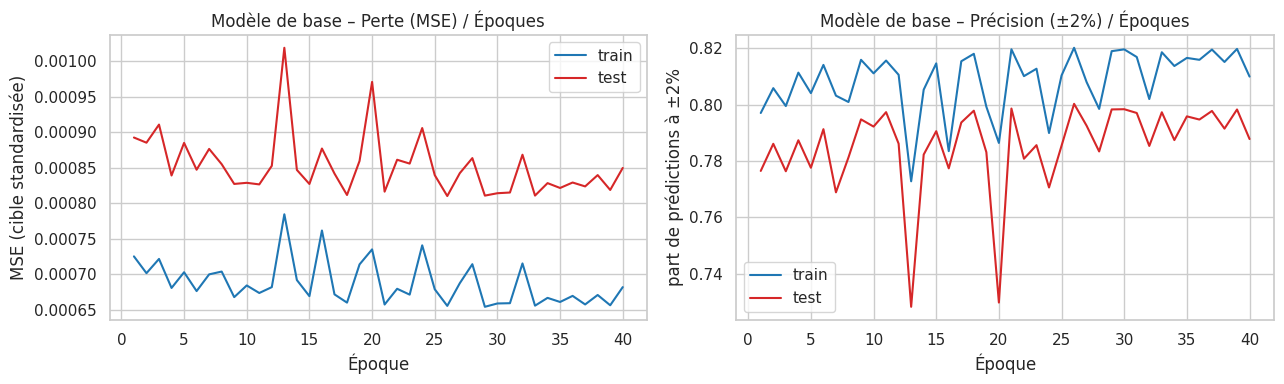

[Modèle de base] perte finale : train = 0.0007 | test = 0.0008 | écart = +0.0002
   précision finale (±2%) : train = 81.0% | test = 78.8%
   meilleure perte test à l'époque 26/40
   → apprentissage globalement sain : pertes train et test proches et faibles.
   → la perte train est stabilisée (< 2 % d'amélioration sur les 5 dernières époques) : plus d'époques apporterait peu.


In [41]:
FINAL_BS = 512
EVAL = {"train": (X_tr, y_tr), "test": (X_te, y_te)}

def plot_curves(model, title):
    h = model.history_
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for k, c in (("train", "tab:blue"), ("test", "tab:red")):
        ax[0].plot(range(1, len(h[k]["loss"]) + 1), h[k]["loss"], c=c, label=k)
        ax[1].plot(range(1, len(h[k]["acc"]) + 1), h[k]["acc"], c=c, label=k)
    ax[0].set_title(f"{title} – Perte (MSE) / Époques"); ax[1].set_title(f"{title} – Précision (±{TOL:.0%}) / Époques")
    for a, yl in zip(ax, ("MSE (cible standardisée)", f"part de prédictions à ±{TOL:.0%}")):
        a.set_xlabel("Époque"); a.set_ylabel(yl); a.legend()
    plt.tight_layout(); plt.show()

def interpret(model, name):
    h = model.history_; tl, te = np.array(h["train"]["loss"]), np.array(h["test"]["loss"])
    ta, tea = np.array(h["train"]["acc"]), np.array(h["test"]["acc"])
    msgs = [f"[{name}] perte finale : train = {tl[-1]:.4f} | test = {te[-1]:.4f} | écart = {te[-1] - tl[-1]:+.4f}",
            f"   précision finale (±{TOL:.0%}) : train = {ta[-1]:.1%} | test = {tea[-1]:.1%}",
            f"   meilleure perte test à l'époque {int(te.argmin()) + 1}/{len(te)}"]
    if te[-1] > 1.3 * tl[-1] and te[-1] > te.min() * 1.1:
        msgs.append("   → signe de SUR-APPRENTISSAGE : la perte test remonte / reste bien au-dessus du train.")
    elif tl[-1] > 0.3:
        msgs.append("   → perte encore élevée : SOUS-APPRENTISSAGE possible (modèle trop simple ou trop peu d'époques).")
    else:
        msgs.append("   → apprentissage globalement sain : pertes train et test proches et faibles.")
    if len(tl) >= 6 and (tl[-6] - tl[-1]) < 0.02 * tl[-6]:
        msgs.append("   → la perte train est stabilisée (< 2 % d'amélioration sur les 5 dernières époques) : plus d'époques apporterait peu.")
    print("\n".join(msgs))

base = TorchMLPRegressor(batch_size=FINAL_BS, tol_scaled=TOL_SCALED, **best_params)
base.fit(X_tr, y_tr, eval_sets=EVAL)
plot_curves(base, "Modèle de base"); interpret(base, "Modèle de base")

### Métriques  et comparaison à la référence naïve



In [42]:
def metrics_price(pred_scaled, y_scaled):
    p, t = to_price(pred_scaled), to_price(y_scaled)
    return {"RMSE ($)": float(np.sqrt(mean_squared_error(t, p))), "MAE ($)": float(mean_absolute_error(t, p)),
            "R²": float(r2_score(t, p)), f"Acc±{TOL:.0%}": float(np.mean(np.abs(np.log(p / t)) <= np.log1p(TOL)))}

def evaluate(model, name):
    return {"Modèle": name,
            **{f"{k} train": v for k, v in metrics_price(model.predict(X_tr), y_tr).items()},
            **{f"{k} test": v for k, v in metrics_price(model.predict(X_te), y_te).items()}}

def naive_row():
    def m(split, y):
        p, t = close_now[split], to_price(y)
        return {"RMSE ($)": float(np.sqrt(mean_squared_error(t, p))), "MAE ($)": float(mean_absolute_error(t, p)),
                "R²": float(r2_score(t, p)), f"Acc±{TOL:.0%}": float(np.mean(np.abs(np.log(p / t)) <= np.log1p(TOL)))}
    return {"Modèle": "Référence naïve (close d'aujourd'hui)",
            **{f"{k} train": v for k, v in m("train", y_tr).items()}, **{f"{k} test": v for k, v in m("test", y_te).items()}}

results = [naive_row(), evaluate(base, "Modèle de base")]
pd.DataFrame(results).set_index("Modèle").round(4)

,RMSE ($) train,MAE ($) train,R² train,Acc±2% train,RMSE ($) test,MAE ($) test,R² test,Acc±2% test
Modèle,,,,,,,,
Référence naïve (close d'aujourd'hui),1.3836,0.6441,0.9995,0.8225,2.2116,0.9934,0.9995,0.8037
Modèle de base,1.5610,0.6885,0.9993,0.8100,2.6889,1.1200,0.9993,0.7878


## 6. Techniques de régularisation


In [43]:
longer = max(int(best_params["epochs"]) * 2, 60)
experiments = {
    "L2 (weight decay 1e-3)": dict(weight_decay=1e-3),
    "Dropout (0.2)": dict(dropout=0.2),
    "BatchNorm": dict(batch_norm=True),
    "Early stopping": dict(epochs=longer, patience=6),
    "Combiné": dict(dropout=0.2, weight_decay=1e-4, batch_norm=True, epochs=longer, patience=6),
}
models = {"Modèle de base": base}
for name, extra in experiments.items():
    m = TorchMLPRegressor(batch_size=FINAL_BS, tol_scaled=TOL_SCALED, **{**best_params, **extra})
    m.fit(X_tr, y_tr, val_set=(X_va, y_va), eval_sets=EVAL)
    models[name] = m; results.append(evaluate(m, name))
    print(f"{name:<24} entraîné ({len(m.history_['train']['loss'])} époques, meilleure époque = {m.best_epoch_})")

table = pd.DataFrame(results).set_index("Modèle")
table["Δ R² (train−test)"] = table["R² train"] - table["R² test"]
display(table.round(4))

L2 (weight decay 1e-3)   entraîné (40 époques, meilleure époque = 40)
Dropout (0.2)            entraîné (40 époques, meilleure époque = 40)
BatchNorm                entraîné (40 époques, meilleure époque = 40)
Early stopping           entraîné (17 époques, meilleure époque = 11)
Combiné                  entraîné (12 époques, meilleure époque = 6)


,RMSE ($) train,MAE ($) train,R² train,Acc±2% train,RMSE ($) test,MAE ($) test,R² test,Acc±2% test,Δ R² (train−test)
Modèle,,,,,,,,,
Référence naïve (close d'aujourd'hui),1.3836,0.6441,0.9995,0.8225,2.2116,0.9934,0.9995,0.8037,-0.0001
Modèle de base,1.5610,0.6885,0.9993,0.8100,2.6889,1.1200,0.9993,0.7878,0.0000
L2 (weight decay 1e-3),1.6892,0.7190,0.9992,0.7801,3.1533,1.1727,0.9991,0.7698,0.0002
Dropout (0.2),13.6520,3.1400,0.9487,0.4783,27.9004,7.2756,0.9258,0.3838,0.0229
BatchNorm,3.2560,0.9727,0.9971,0.7699,6.6219,1.9433,0.9958,0.7096,0.0013
Early stopping,1.4168,0.6590,0.9994,0.8157,2.2699,1.0204,0.9995,0.7974,-0.0001
Combiné,2.8401,1.1710,0.9978,0.5249,5.4981,1.9367,0.9971,0.5762,0.0007


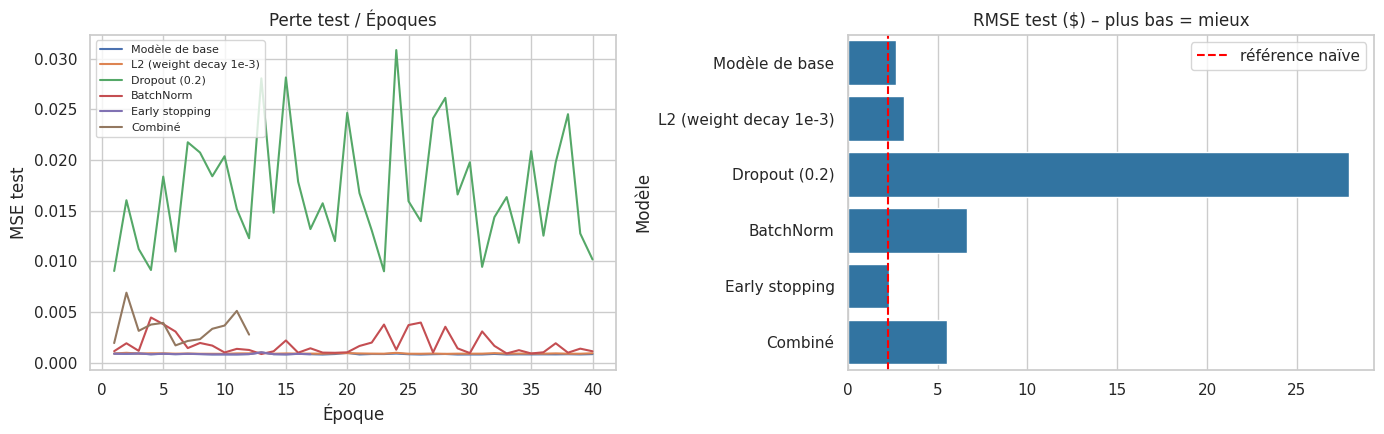

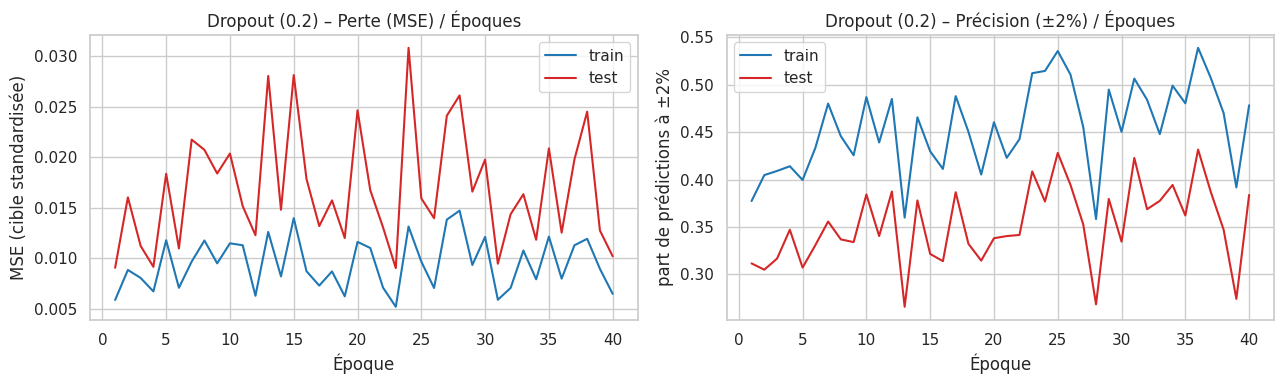

[Dropout (0.2)] perte finale : train = 0.0065 | test = 0.0102 | écart = +0.0037
   précision finale (±2%) : train = 47.8% | test = 38.4%
   meilleure perte test à l'époque 23/40
   → signe de SUR-APPRENTISSAGE : la perte test remonte / reste bien au-dessus du train.


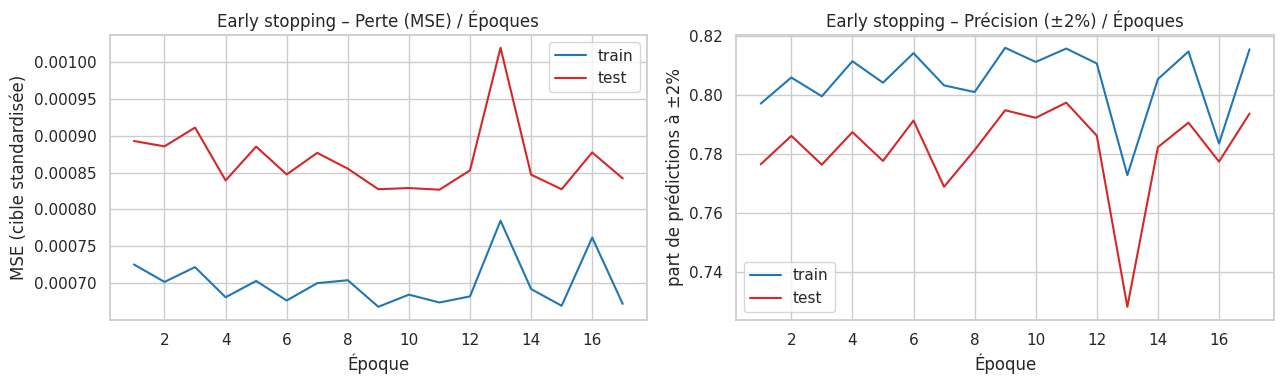

[Early stopping] perte finale : train = 0.0007 | test = 0.0008 | écart = +0.0002
   précision finale (±2%) : train = 81.5% | test = 79.4%
   meilleure perte test à l'époque 11/17
   → apprentissage globalement sain : pertes train et test proches et faibles.
   → la perte train est stabilisée (< 2 % d'amélioration sur les 5 dernières époques) : plus d'époques apporterait peu.


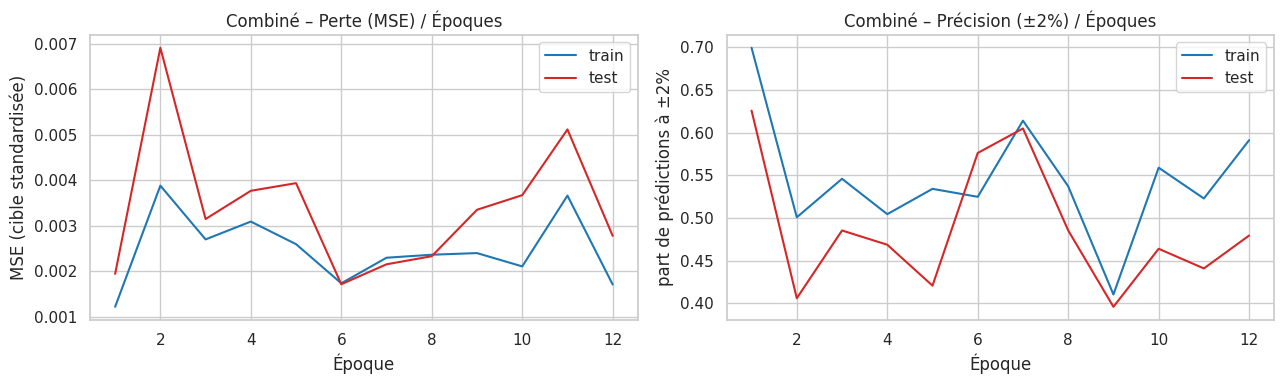

[Combiné] perte finale : train = 0.0017 | test = 0.0028 | écart = +0.0011
   précision finale (±2%) : train = 59.1% | test = 48.0%
   meilleure perte test à l'époque 6/12
   → signe de SUR-APPRENTISSAGE : la perte test remonte / reste bien au-dessus du train.


In [44]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for name, m in models.items():
    ax[0].plot(range(1, len(m.history_["test"]["loss"]) + 1), m.history_["test"]["loss"], label=name)
ax[0].set_title("Perte test / Époques"); ax[0].set_xlabel("Époque"); ax[0].set_ylabel("MSE test"); ax[0].legend(fontsize=8)
t = table.drop(index="Référence naïve (close d'aujourd'hui)", errors="ignore")
sns.barplot(x=t["RMSE ($) test"].values, y=t.index, ax=ax[1], color="tab:blue")
ax[1].axvline(table.loc["Référence naïve (close d'aujourd'hui)", "RMSE ($) test"], c="red", ls="--", label="référence naïve")
ax[1].set_title("RMSE test ($) – plus bas = mieux"); ax[1].legend()
plt.tight_layout(); plt.show()

for name in ["Dropout (0.2)", "Early stopping", "Combiné"]:
    plot_curves(models[name], name); interpret(models[name], name)

Meilleur modèle selon la RMSE test : Early stopping


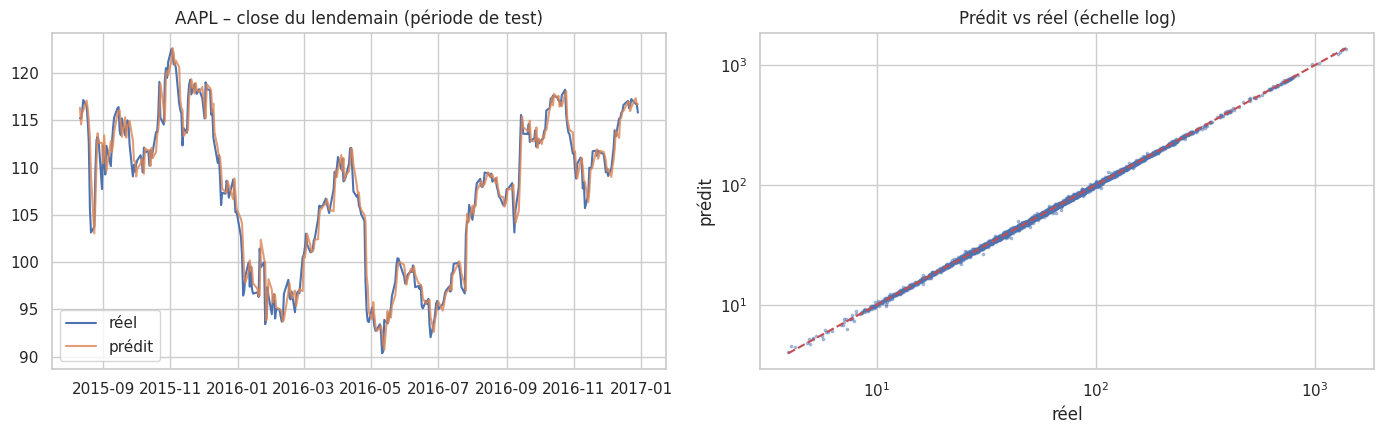

In [45]:
cand = table.drop(index="Référence naïve (close d'aujourd'hui)", errors="ignore")
best_name = cand["RMSE ($) test"].idxmin(); best_model = models[best_name]
print("Meilleur modèle selon la RMSE test :", best_name)

pred_te = to_price(best_model.predict(X_te)); true_te = to_price(y_te)
sym = syms[0]; mask = (meta_te["symbol"] == sym).values
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(meta_te.loc[mask, "date"], true_te[mask], label="réel"); ax[0].plot(meta_te.loc[mask, "date"], pred_te[mask], label="prédit", alpha=.8)
ax[0].set_title(f"{sym} – close du lendemain (période de test)"); ax[0].legend()
s = rng.choice(len(true_te), size=min(5000, len(true_te)), replace=False)
ax[1].scatter(true_te[s], pred_te[s], s=3, alpha=.4); lim = [true_te[s].min(), true_te[s].max()]
ax[1].plot(lim, lim, "r--"); ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_title("Prédit vs réel (échelle log)"); ax[1].set_xlabel("réel"); ax[1].set_ylabel("prédit")
plt.tight_layout(); plt.show()

In [46]:
# Sauvegarde des résultats pour le rapport (README)
os.makedirs("results", exist_ok=True)
table.round(4).to_csv("results/part1_regression_results.csv")
print(table.round(4).to_string())
print("\nMeilleurs hyperparamètres :", best_params)

                                       RMSE ($) train  MAE ($) train  R² train  Acc±2% train  RMSE ($) test  MAE ($) test  R² test  Acc±2% test  Δ R² (train−test)
Modèle                                                                                                                                                            
Référence naïve (close d'aujourd'hui)          1.3836         0.6441    0.9995        0.8225         2.2116        0.9934   0.9995       0.8037            -0.0001
Modèle de base                                 1.5610         0.6885    0.9993        0.8100         2.6889        1.1200   0.9993       0.7878             0.0000
L2 (weight decay 1e-3)                         1.6892         0.7190    0.9992        0.7801         3.1533        1.1727   0.9991       0.7698             0.0002
Dropout (0.2)                                 13.6520         3.1400    0.9487        0.4783        27.9004        7.2756   0.9258       0.3838             0.0229
BatchNorm             